 # Veri Odaklı Futbol Analitiği: Premier Lig Maç Sonucu Tahmini
Bu proje, İngiltere Premier Lig maçlarındaki ev sahibi takımın **isabetli şut, korner ve faul** istatistiklerini kullanarak maç sonucunu tahmin eden bir Makine Öğrenmesi (Karar Ağacı) uygulamasıdır.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

## Aşama 2: Veri Toplama ve Hazırlama
Kaggle'dan elde edilen ham veri seti sisteme yüklenir. Hedef odaklı ilerlemek için sadece 4 sütun seçilmiş ve veri kaybını önlemek amacıyla eksik (NaN) değerler, ilgili sütunların **ortalaması (mean)** ile doldurulmuştur.

In [4]:
df = pd.read_csv('epl_final.csv')

df = df[['HomeShotsOnTarget', 'HomeCorners', 'HomeFouls', 'FullTimeResult']]

df.fillna(df.mean(numeric_only=True), inplace=True)
df['FullTimeResult'].fillna('D', inplace=True)

/tmp/ipykernel_643/233413840.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['FullTimeResult'].fillna('D', inplace=True)


## Aşama 3: Keşifçi Veri Analizi (EDA) ve Görselleştirme
Veri setinin temel istatistikleri çıkarılmış, maç sonuçlarının genel dağılımı (Bar Chart) ve takımın şut/faul agresiflik ilişkisi (Scatter Plot) görselleştirilmiştir.

Veri Seti İstatistiksel Özeti
       HomeShotsOnTarget  HomeCorners    HomeFouls
count        9380.000000  9380.000000  9380.000000
mean            5.973134     6.040299    11.276333
std             3.267954     3.110619     3.750250
min             0.000000     0.000000     0.000000
25%             4.000000     4.000000     9.000000
50%             6.000000     6.000000    11.000000
75%             8.000000     8.000000    14.000000
max            24.000000    20.000000    33.000000


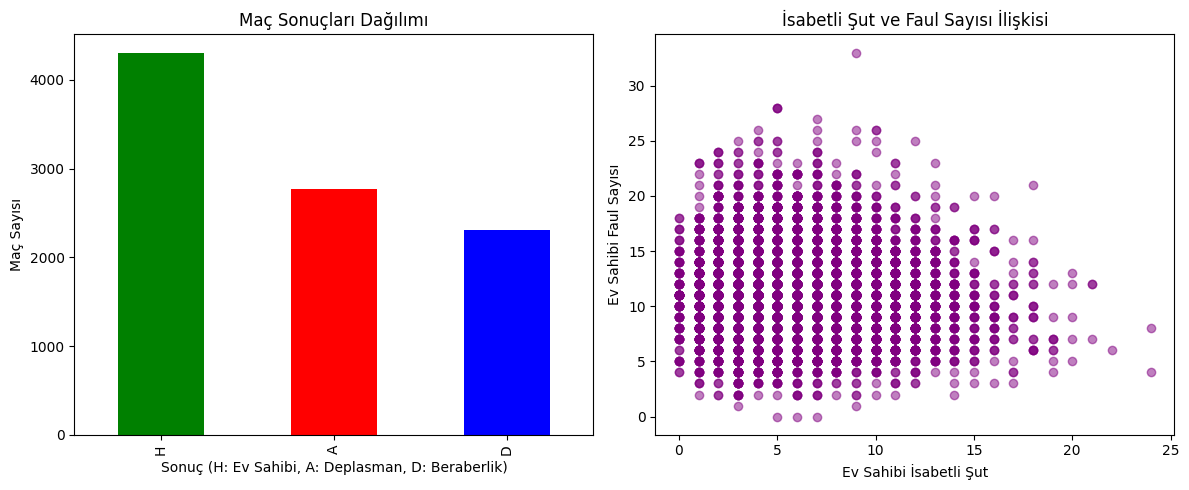

In [5]:
print("Veri Seti İstatistiksel Özeti")
print(df.describe())

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
df['FullTimeResult'].value_counts().plot(kind='bar', color=['green', 'red', 'blue'])
plt.title("Maç Sonuçları Dağılımı")
plt.xlabel("Sonuç (H: Ev Sahibi, A: Deplasman, D: Beraberlik)")
plt.ylabel("Maç Sayısı")

plt.subplot(1, 2, 2)
plt.scatter(df['HomeShotsOnTarget'], df['HomeFouls'], alpha=0.5, c='purple')
plt.title("İsabetli Şut ve Faul Sayısı İlişkisi")
plt.xlabel("Ev Sahibi İsabetli Şut")
plt.ylabel("Ev Sahibi Faul Sayısı")

plt.tight_layout()
plt.show()

## Aşama 4 & 5: Model Kurma ve Değerlendirme
Veri seti, modelin ezberlemesini önlemek için %80 Eğitim ve %20 Test olarak ikiye ayrılmıştır. Sınıflandırma problemi olduğu için **Decision Tree (Karar Ağacı)** algoritması kullanılarak başarı oranı ölçülmüştür.

In [8]:
X = df[['HomeShotsOnTarget', 'HomeCorners', 'HomeFouls']]
y = df['FullTimeResult']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = DecisionTreeClassifier(max_depth=5)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
basari = accuracy_score(y_test, y_pred)
print(f"Model Başarı Oranı: %{basari * 100:.2f}")

Model Başarı Oranı: %50.32


## Aşama 6: Akıllı Tahmin Aracı
Eğitilen model, kullanıcıdan alınan yepyeni değerlerle canlı tahmin üretmek üzere interaktif bir fonksiyona dönüştürülmüştür.

In [7]:
def tahmin_et():

    isabetli_sut = float(input("Ev sahibi takımın beklenen isabetli şut sayısı: "))
    korner = float(input("Ev sahibi takımın beklenen korner sayısı: "))
    faul = float(input("Ev sahibi takımın beklenen faul sayısı: "))

    girdi_tablosu = pd.DataFrame([[isabetli_sut, korner, faul]], columns=['HomeShotsOnTarget', 'HomeCorners', 'HomeFouls'])
    tahmin_kodu = model.predict(girdi_tablosu)[0]

    if tahmin_kodu == 'H':
        sonuc = "Ev Sahibi Kazanır"
    elif tahmin_kodu == 'A':
        sonuc = "Deplasman Takımı Kazanır"
    else:
        sonuc = "Berabere Biter"

    print(f"\n=> Analiz Sonucu: Girdiğiniz istatistiklere göre bu maç yüksek ihtimalle {sonuc}!")

tahmin_et()

Ev sahibi takımın beklenen isabetli şut sayısı: 5
Ev sahibi takımın beklenen korner sayısı: 3
Ev sahibi takımın beklenen faul sayısı: 8

=> Analiz Sonucu: Girdiğiniz istatistiklere göre bu maç yüksek ihtimalle Ev Sahibi Kazanır!
